<img src="https://raw.githubusercontent.com/riazcseiu/fmlds2026-multimodal-workshop/main/assets/banner.png" width="100%">

# Notebook 2 · Sentiment → Adaptive Weighting
**Making the language signal fair**  ·  ⏱ about 15 minutes

### What you will learn
- Score every utterance with a **lexicon model** (VADER) and a **transformer** (RoBERTa)
- Measure the **modality effect** — are on-site visitors more positive than video viewers?
- Implement the **adaptive per-participant weighting** of World 2026 (§4.2): personalised decay, sentiment scaling, verbosity normalisation
- Quantify how much verbosity bias the adaptive model removes

> **The story so far.** At the *Imagine Coffee Event* — a two-hour Sunday-morning pop-up market in Matsue, Japan — we asked visitors what they noticed (**interviews → language**) and we filmed what they actually did (**video → vision**).
> This workshop combines both modalities to answer one question: *do people do what they say?*

<small>Data: a reduced, anonymised teaching subset derived from Mian & Nguyen-Tran (World 2026) and Nguyen-Tran, Majiid & Mian (World 2025). Names removed, participants sub-sampled, ~10% of utterances dropped. Do not use for research claims.</small>


In [1]:
# ▶ Run this cell first — it fetches the workshop data (about 20 s in Colab)
import os, sys, warnings
warnings.filterwarnings('ignore')
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/riazcseiu/fmlds2026-multimodal-workshop'
if IN_COLAB:
    if not os.path.exists('fmlds2026-multimodal-workshop'):
        os.system(f'git clone -q --depth 1 {REPO_URL}')
    BASE = 'fmlds2026-multimodal-workshop'
else:
    BASE = '..'          # running locally from the notebooks/ folder
DATA = os.path.join(BASE, 'data')
RESULTS = os.path.join(BASE, 'data', 'results'); os.makedirs(RESULTS, exist_ok=True)

import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 11})
COL = {'onsite': '#2A9D8F', 'video': '#4361EE', 'virtual': '#9B5DE5', 'P': '#4361EE', 'B': '#D9731A'}
print('Data folder:', os.path.abspath(DATA))

In [2]:
import re
df = pd.read_csv(f'{DATA}/interviews/imagine_coffee_all.csv')
part = df[df.role == 'participant'].copy()
print(part.modality.value_counts().to_string())

modality
virtual    210
video      161
onsite      88


## 1 · Two ways to read emotion from text
- **VADER** — a hand-built lexicon of ~7,500 words with intensity rules. Fast, transparent, no GPU.
- **RoBERTa (cardiffnlp/twitter-roberta-base-sentiment-latest)** — a transformer fine-tuned on ~124 M tweets. Understands context ("not bad" ≠ "bad").

In [3]:
try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
except ImportError:
    os.system('pip -q install vaderSentiment')
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
part['vader'] = part.text.astype(str).map(lambda t: vader.polarity_scores(t)['compound'])
part['vader_label'] = pd.cut(part.vader, [-1.01, -0.05, 0.05, 1.01], labels=['negative', 'neutral', 'positive'])
part[['modality', 'text', 'vader', 'vader_label']].sample(6, random_state=7)

,modality,text,vader,vader_label
929,virtual,"Makanae? Ah, Makanae don. So it's like, you kn...",0.4173,positive
536,virtual,"Yes, and, um, Um, well, maybe I have to rememb...",0.8658,positive
174,onsite,I would be better to have more touchable and c...,0.9287,positive
788,virtual,"Yeah, I think I have, yeah.",0.5267,positive
641,virtual,"I see people selling Um, um, drink?",0.0000,neutral
169,onsite,I enjoy more prominent colors such as red. I w...,0.8802,positive


In [ ]:
# Transformer sentiment — needs internet to download the model (~500 MB, ~1 min in Colab; GPU optional)
try:
    from transformers import pipeline
    clf = pipeline('sentiment-analysis', model='cardiffnlp/twitter-roberta-base-sentiment-latest',
                   truncation=True, max_length=256)
    preds = clf(part.text.astype(str).tolist(), batch_size=32)
    part['roberta_label'] = [p['label'].lower() for p in preds]
    part['roberta_conf'] = [p['score'] for p in preds]
    HAVE_ROBERTA = True
except Exception as e:
    print('Transformer not available here (', type(e).__name__, ') — continuing with VADER only.')
    part['roberta_label'] = part.vader_label.astype(str); HAVE_ROBERTA = False

In [ ]:
if HAVE_ROBERTA:
    ct = pd.crosstab(part.vader_label, part.roberta_label, normalize='index').round(2)
    print('Agreement (rows = VADER, columns = RoBERTa):'); display(ct)
    dis = part[part.vader_label.astype(str) != part.roberta_label]
    display(dis[['text', 'vader_label', 'roberta_label']].head(8))

**Discuss:** look at the disagreements. Which model is right? Spoken, hesitant speech ("uh, not really, maybe") is hard for both.

## 2 · The modality effect
The paper found on-site participants were noticeably more positive than video viewers — the *festive-atmosphere bias*. Does our teaching subset show the same?

In [ ]:
lab = 'roberta_label' if HAVE_ROBERTA else 'vader_label'
share = (pd.crosstab(part.modality, part[lab].astype(str), normalize='index') * 100).reindex(['onsite', 'video', 'virtual'])
share = share.reindex(columns=[c for c in ['negative', 'neutral', 'positive'] if c in share.columns])
ax = share.plot.barh(stacked=True, figsize=(8, 2.6), color=['#E76F51', '#C9CCD4', '#2A9D8F'])
ax.set_xlabel('% of participant utterances'); ax.set_title(f'Sentiment by interview modality ({lab.split("_")[0]})')
ax.legend(loc='lower right', ncol=3, fontsize=8); plt.tight_layout(); plt.show()
share.round(1)

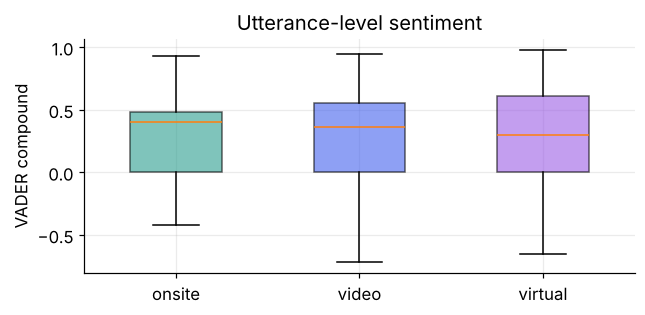

In [7]:
fig, ax = plt.subplots(figsize=(6, 3))
for i, m in enumerate(['onsite', 'video', 'virtual']):
    v = part[part.modality == m].vader
    ax.boxplot(v, positions=[i], widths=.5, patch_artist=True, boxprops=dict(facecolor=COL[m], alpha=.6))
ax.set_xticks(range(3)); ax.set_xticklabels(['onsite', 'video', 'virtual']); ax.set_ylabel('VADER compound')
ax.set_title('Utterance-level sentiment'); plt.tight_layout(); plt.show()

## 3 · Where is the negativity?
Sentiment becomes useful when it is attached to **what** people talk about.

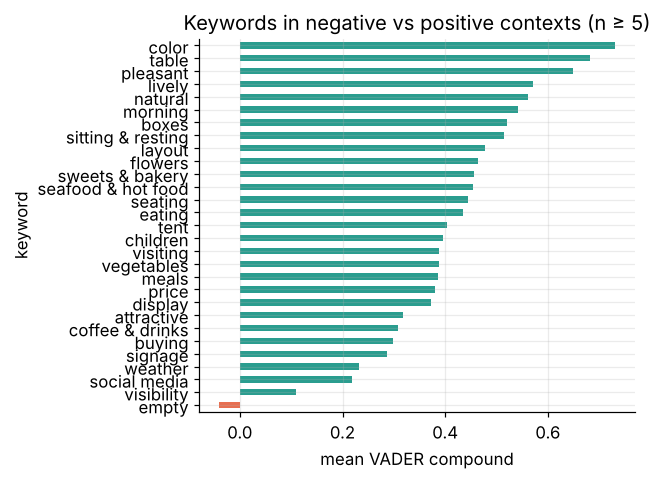

In [8]:
kw = pd.read_csv(f'{DATA}/keywords/keyword_dictionary.csv'); kw['variants'] = kw.variants.str.split('|')
pats = [(r.category, r.keyword, re.compile(r'\b(' + '|'.join(map(re.escape, r.variants)) + r')\b', re.I)) for r in kw.itertuples()]
rows = []
for r in part.itertuples():
    for cat, key, p in pats:
        if p.search(str(r.text)):
            rows.append(dict(modality=r.modality, session=r.session, turn=r.turn, category=cat, keyword=key,
                             vader=r.vader, label=str(getattr(r, lab))))
men = pd.DataFrame(rows)
ks = men.groupby('keyword').agg(n=('vader', 'size'), mean_sentiment=('vader', 'mean')).query('n >= 5').sort_values('mean_sentiment')
ax = ks.mean_sentiment.plot.barh(figsize=(6, 4.5), color=np.where(ks.mean_sentiment < 0, '#E76F51', '#2A9D8F'))
ax.set_xlabel('mean VADER compound'); ax.set_title('Keywords in negative vs positive contexts (n ≥ 5)'); plt.tight_layout(); plt.show()

## 4 · Adaptive per-participant weighting  (World 2026, §4.2)
The baseline gave everybody the same decay δ = 0.25, so talkative people piled up points. The adaptive model changes three things:

| Step | What happens | Formula |
|---|---|---|
| 1 · Verbosity | count each participant's keyword mentions $M_p$ | |
| 2 · Personal decay | concise → gentle decay, verbose → steep decay | $\delta_p \in [0.15,\,0.35]$ (linear in $M_p$) |
| 3 · Base weights | as before but with $\delta_p$, cap $K_{max}=4$ | $b(r)=\max(0, 1-\delta_p (r-1))$ |
| 4 · Sentiment scaling | positive ×1.2, neutral ×1.0, negative ×0.8 | $(1+\sigma\,\mathrm{sgn}(\bar s_{p,c}))$, $\sigma=0.2$ |
| 5 · Normalise | divide by the square root of utterance count | $S_{p,c} / N_p^{\,\nu}$, $\nu = 0.5$ |

In [9]:
D_MIN, D_MAX, K_MAX, SIGMA, NU = 0.15, 0.35, 4, 0.2, 0.5
s5 = lambda c: 1.0 if c >= .5 else .75 if c >= .05 else .5 if c > -.05 else .25 if c > -.5 else 0.0
men['s'] = men.vader.map(s5)
N_utt = part.groupby(['modality', 'session']).size().rename('N')

def score(men, adaptive=True):
    m = men.sort_values(['modality', 'session', 'turn']).copy()
    M = m.groupby(['modality', 'session']).size().rename('M')
    m = m.join(M, on=['modality', 'session'])
    if adaptive:   # step 2: personalised decay within each modality
        lo, hi = m.groupby('modality').M.transform('min'), m.groupby('modality').M.transform('max')
        m['delta'] = D_MIN + (D_MAX - D_MIN) * (m.M - lo) / (hi - lo).replace(0, 1)
    else:
        m['delta'] = 0.25
    m['r'] = m.groupby(['modality', 'session', 'category']).cumcount() + 1
    m['b'] = np.where(m.r <= K_MAX, np.maximum(0, 1 - m.delta * (m.r - 1)), 0)
    m['w'] = m.b * m.s
    S = m.groupby(['modality', 'session', 'category']).agg(S=('w', 'sum'), sbar=('s', 'mean'), delta=('delta', 'first')).reset_index()
    if adaptive:   # steps 4-5
        S['S'] *= 1 + SIGMA * np.sign(S.sbar - 0.5)
        S = S.join(N_utt, on=['modality', 'session']); S['S'] /= S.N ** NU
    return S

base, adap = score(men, adaptive=False), score(men, adaptive=True)
adap.groupby(['modality', 'session']).delta.first().round(2).unstack(0)

modality,onsite,video,virtual
session,,,
R01,NaN,0.27,0.35
R02,NaN,0.17,0.15
R03,NaN,0.15,0.22
R04,NaN,0.35,0.30
S01,0.16,NaN,NaN
S02,0.18,NaN,NaN
S03,0.20,NaN,NaN
S04,0.15,NaN,NaN
S05,0.15,NaN,NaN


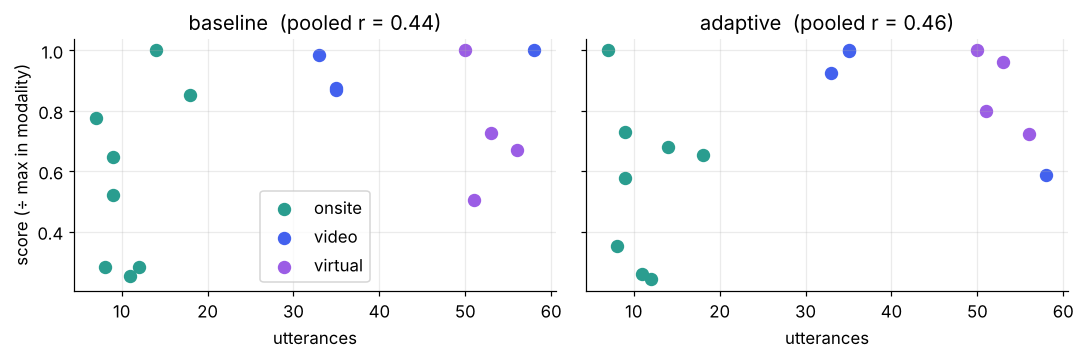

In [10]:
tb = base.groupby(['modality', 'session']).S.sum().rename('baseline')
ta = adap.groupby(['modality', 'session']).S.sum().rename('adaptive')
cmp_ = pd.concat([tb, ta, N_utt], axis=1).dropna().reset_index()
for c in ['baseline', 'adaptive']:   # rescale within modality so the two are comparable
    cmp_[c + '_norm'] = cmp_.groupby('modality')[c].transform(lambda x: x / x.max())

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, c in zip(axs, ['baseline_norm', 'adaptive_norm']):
    for m in ['onsite', 'video', 'virtual']:
        d = cmp_[cmp_.modality == m]; ax.scatter(d.N, d[c], s=60, color=COL[m], label=m)
    r = cmp_[['N', c]].corr().iloc[0, 1]
    ax.set_title(f'{c.split("_")[0]}  (pooled r = {r:.2f})'); ax.set_xlabel('utterances')
axs[0].set_ylabel('score (÷ max in modality)'); axs[0].legend(); plt.tight_layout(); plt.show()

In [11]:
def within_r(frame, col):
    return frame.groupby('modality').apply(lambda g: g[['N', col]].corr().iloc[0, 1])
top_share = lambda x: x.max() / x.sum()
res = pd.DataFrame({
    'r_baseline': within_r(cmp_, 'baseline'), 'r_adaptive': within_r(cmp_, 'adaptive'),
    'top_speaker_share_baseline': cmp_.groupby('modality').baseline.apply(top_share),
    'top_speaker_share_adaptive': cmp_.groupby('modality').adaptive.apply(top_share)}).reindex(['onsite', 'video', 'virtual'])
res.round(2)

,r_baseline,r_adaptive,top_speaker_share_baseline,top_speaker_share_adaptive
modality,,,,
onsite,0.41,-0.12,0.22,0.22
video,0.58,-0.97,0.27,0.29
virtual,-0.34,-0.66,0.35,0.29


**Reading the result.**
- `r` = correlation between *how much someone spoke* and *their score*. Near **0** = verbosity no longer drives the score. Strongly **negative** = we now *punish* talkative people (over-correction).
- `top_speaker_share` = how much of the modality's total score belongs to the single highest scorer.

With only 4–8 people per modality the numbers jump around — the paper reports a ~45 % reduction in verbosity-driven inflation on the full dataset. Look at the **video** row: with ν = 0.5 the most talkative participant (R04) may now fall to the bottom. Is that fair? Try ν = 0.3 below.

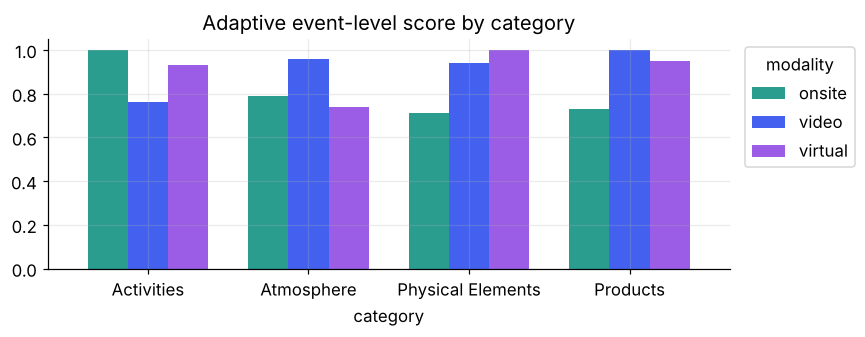

In [12]:
W_ad = adap.groupby(['modality', 'category']).S.mean().unstack(0).reindex(columns=['onsite', 'video', 'virtual'])
(W_ad / W_ad.max()).round(2).plot.bar(figsize=(8, 3.2), color=[COL[c] for c in W_ad.columns], width=.75)
plt.title('Adaptive event-level score by category'); plt.legend(title='modality', bbox_to_anchor=(1.01, 1), loc='upper left'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
adap.to_csv(f'{RESULTS}/nb2_adaptive_scores.csv', index=False)
part.to_csv(f'{RESULTS}/nb2_utterance_sentiment.csv', index=False)

## ✏️ Try it yourself (3 min)
1. Set `NU = 1.0` (full normalisation). Is that fair to someone who genuinely had a lot to say?
2. Set `SIGMA = 0.5`. How much does sentiment start to dominate?
3. Compare **R04** (native Japanese speaker) with R01–R03. Different vocabulary? Different sentiment?

**Next →** `03_vision_tracking.ipynb` — from what people **said** to what they **did**.